## Exercise 15.2 (Explore the dataset)  

1. Pretend that you did not read the Subgroup failures paragraph in the description. Explore the dataset and find insights related to the different failure types.
2. Do your findings align with the description given in the Subgroup failures paragraph?
3. Compute summary statistics for each feature grouped by failure type.
4. Create at least two visualizations (e.g., histograms, box plots) that reveal differences between failure types.
5. If you are able to isolate failing samples, note down the thresholds; you will need them in Milestone 4.

1. Pretend that you did not read the Subgroup failures paragraph in the description. Explore the dataset and find insights related to the different failure types.

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("XAI_Drilling_Dataset.csv")

numeric_features = [
    "Cutting speed vc [m/min]",
    "Spindle speed n [1/min]",
    "Feed f [mm/rev]",
    "Feed rate vf [mm/min]",
    "Power Pc [kW]",
    "Cooling [%]",
    "Process Time [sec]"
]

df.head()

,ID,Cutting speed vc [m/min],Spindle speed n [1/min],Feed f [mm/rev],Feed rate vf [mm/min],Power Pc [kW],Cooling [%],Material,Drill Bit Type,Process Time [sec],Main Failure,BEF,CCF,FWF,WDF
0,1,29.92,794,0.218,173,194.87,75,N,W,19.26,0,0,0,0,0
1,2,29.85,792,0.241,191,214.71,75,N,W,19.55,0,0,0,0,0
2,3,22.85,606,0.183,111,95.68,50,P,N,36.16,0,0,0,0,0
3,4,29.60,785,0.236,237,206.93,75,N,W,21.22,1,0,0,1,0
4,5,17.43,462,0.246,114,74.85,50,K,H,33.56,0,0,0,0,0


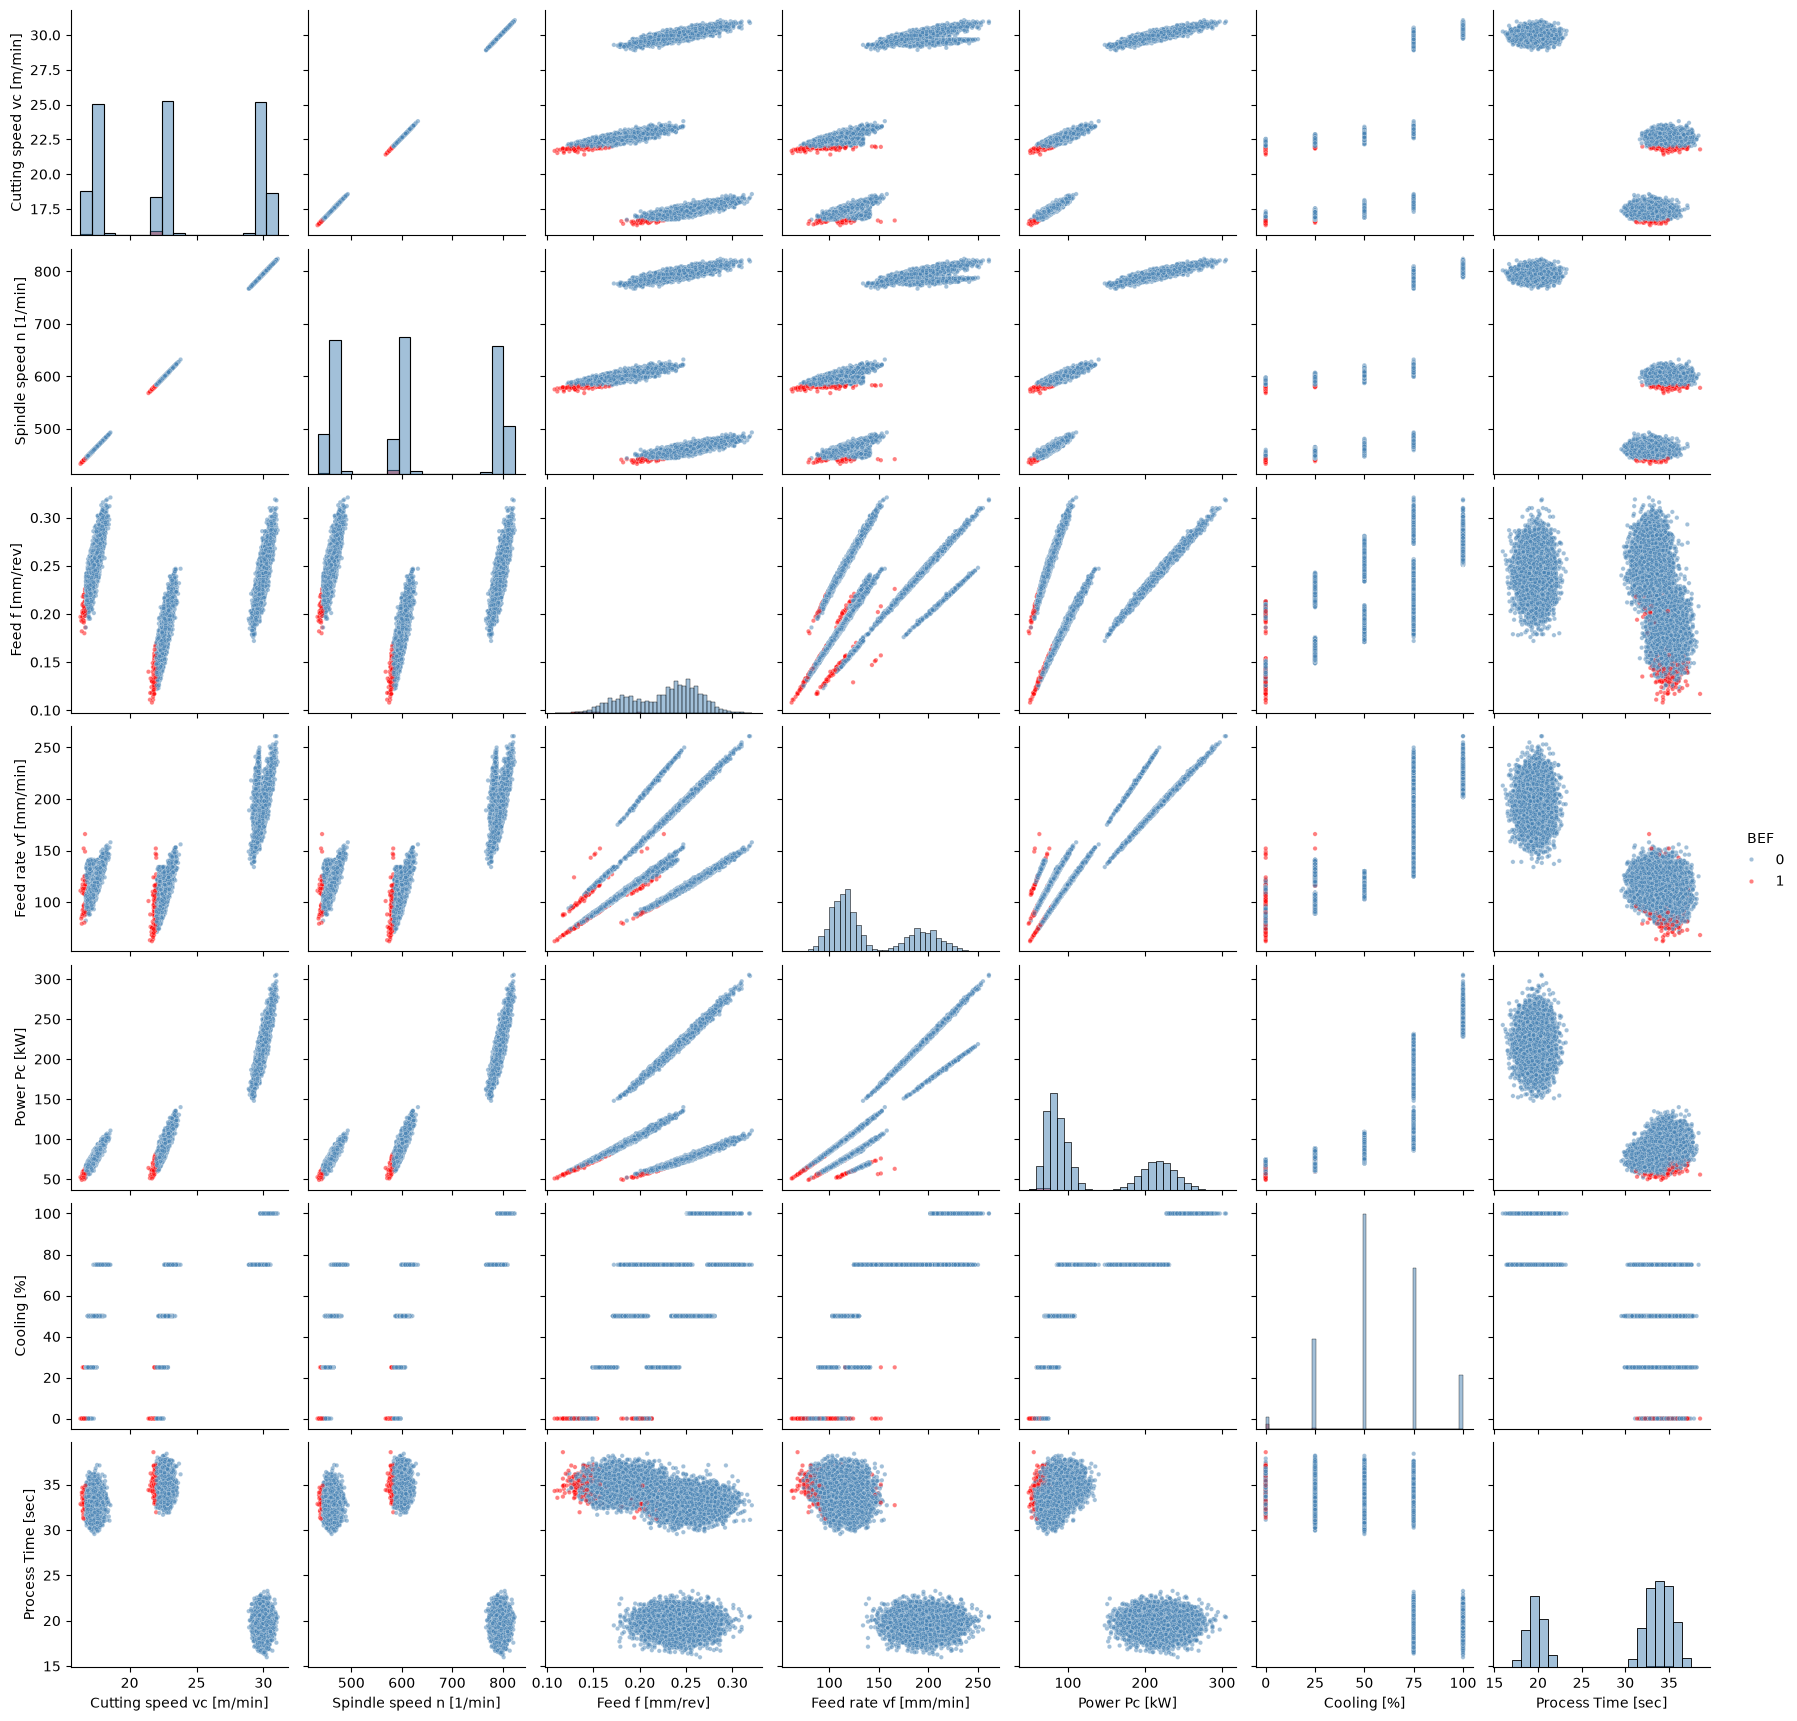

In [5]:
# Pairplot für BEF-Fehler erstellen
sns.pairplot(
data=df,                                    # Datensatz               
    vars=numeric_features,                  # Auswahl der numerischen Features
    hue="BEF",                              # Farbe nach BEF-Fehlern
    palette={0: "steelblue", 1: "red"},     # Farbpalette für die Klassen
    diag_kind="hist",                       # Histogramme auf der Diagonalen
    plot_kws={"alpha": 0.5, "s": 10}        # Transparenz und Punktgröße für die Scatterplots
)

plt.show()

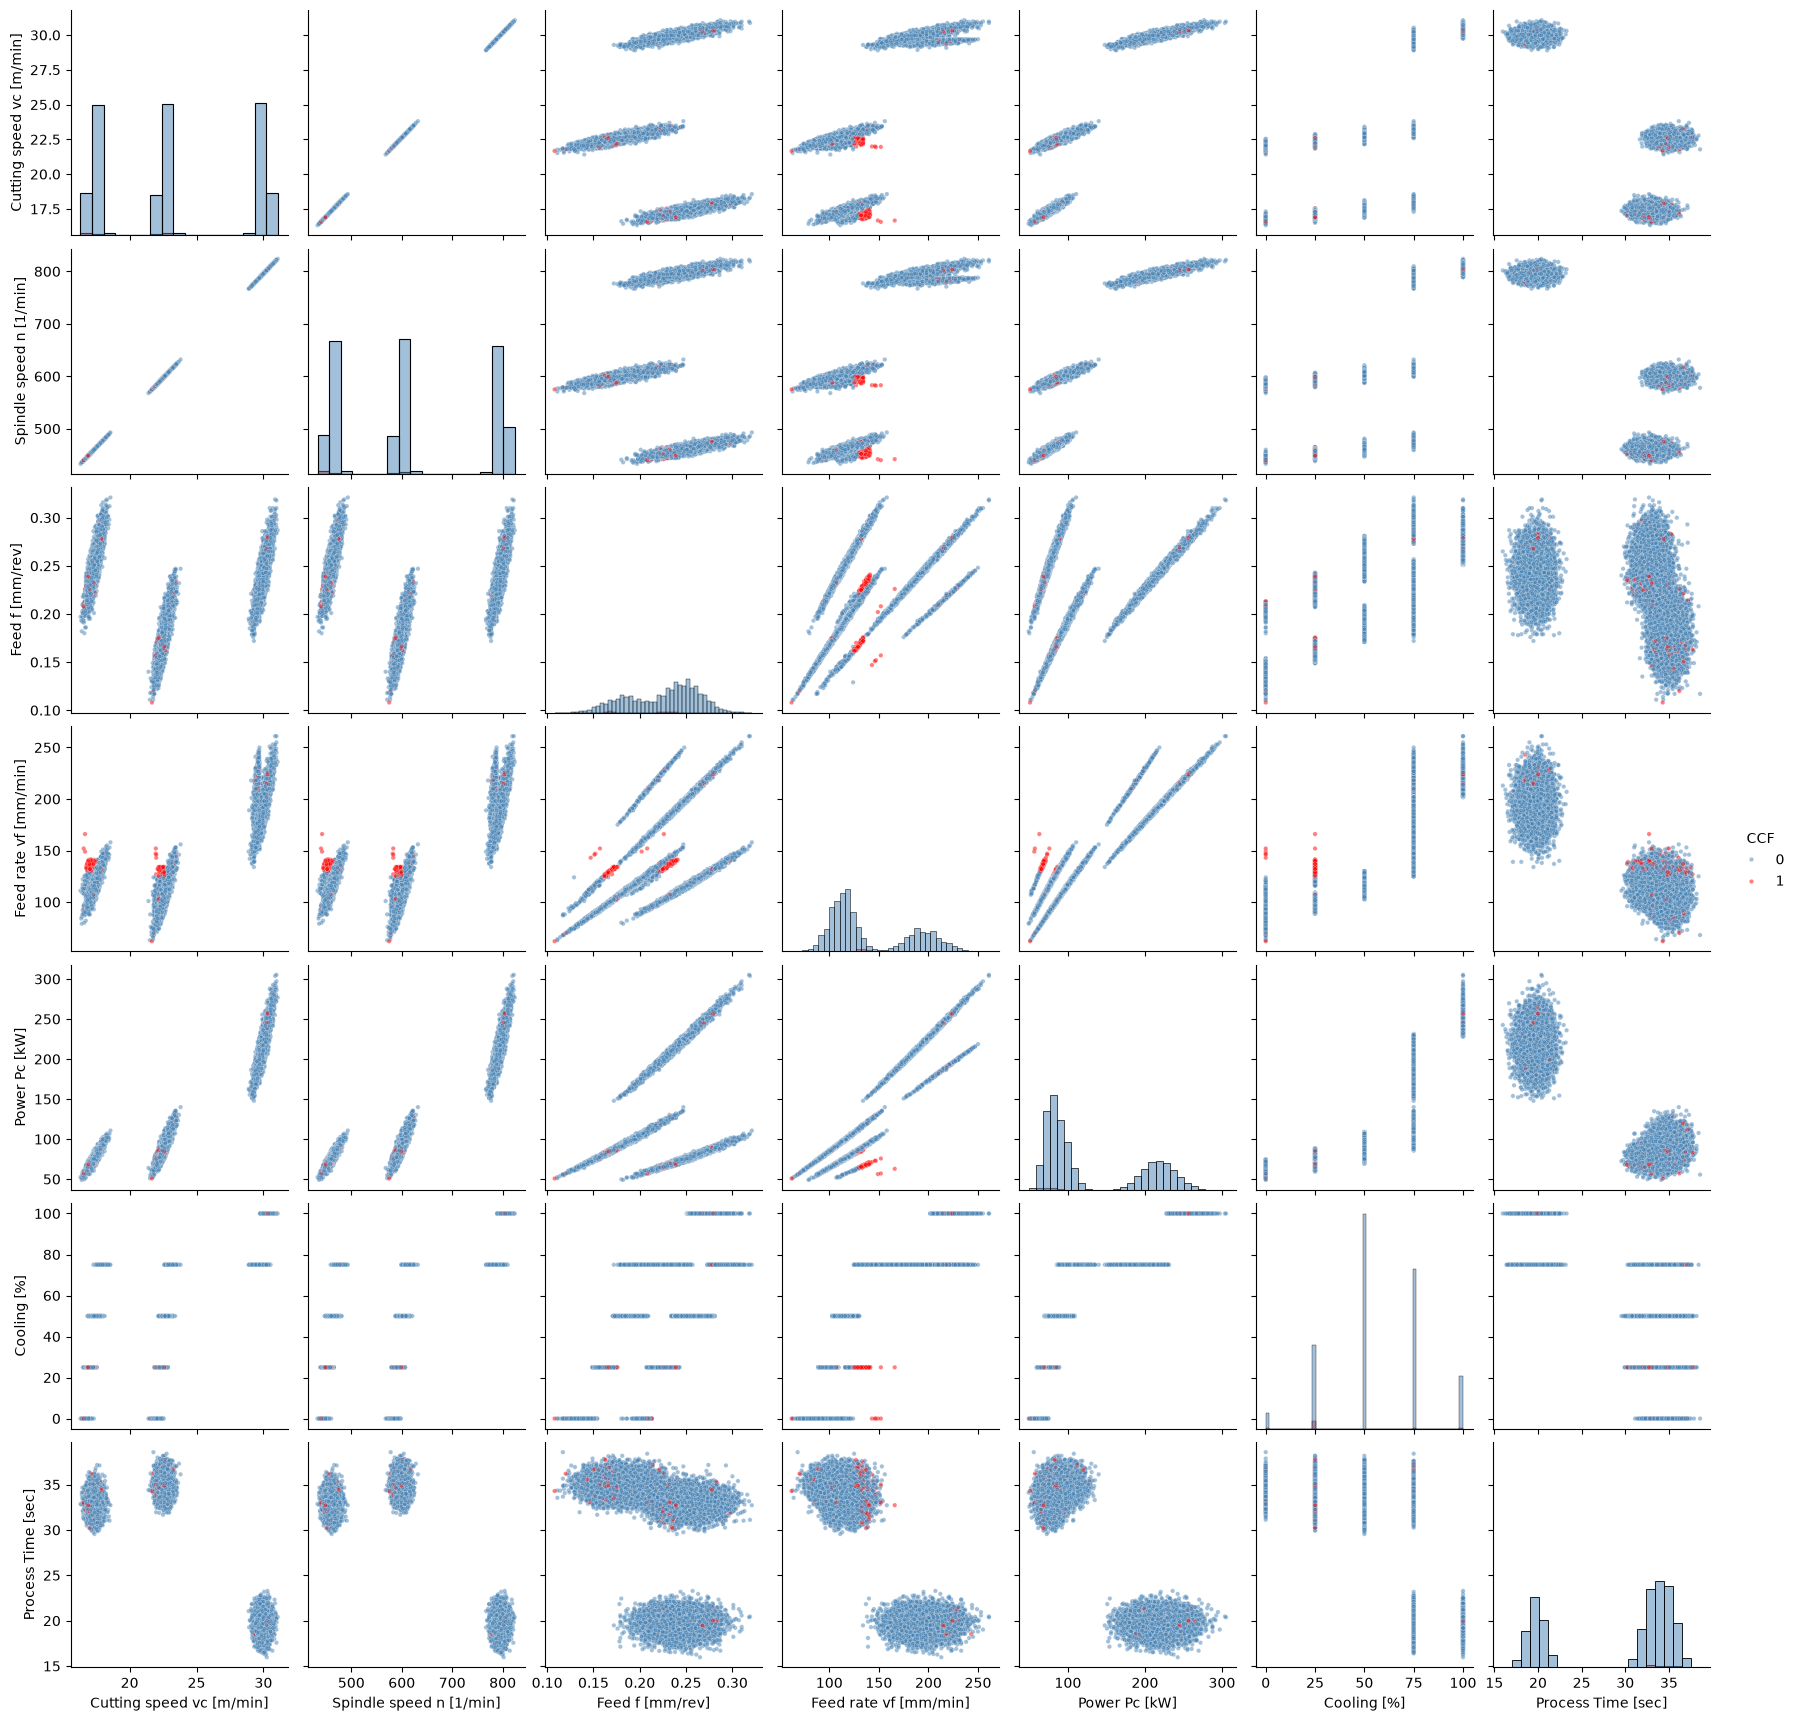

In [6]:
# Pairplot für CCF-Fehler erstellen
sns.pairplot(
    data=df,
    vars=numeric_features,
    hue="CCF",
    palette={0: "steelblue", 1: "red"},
    diag_kind="hist",
    plot_kws={"alpha": 0.5, "s": 10}
)

plt.show()

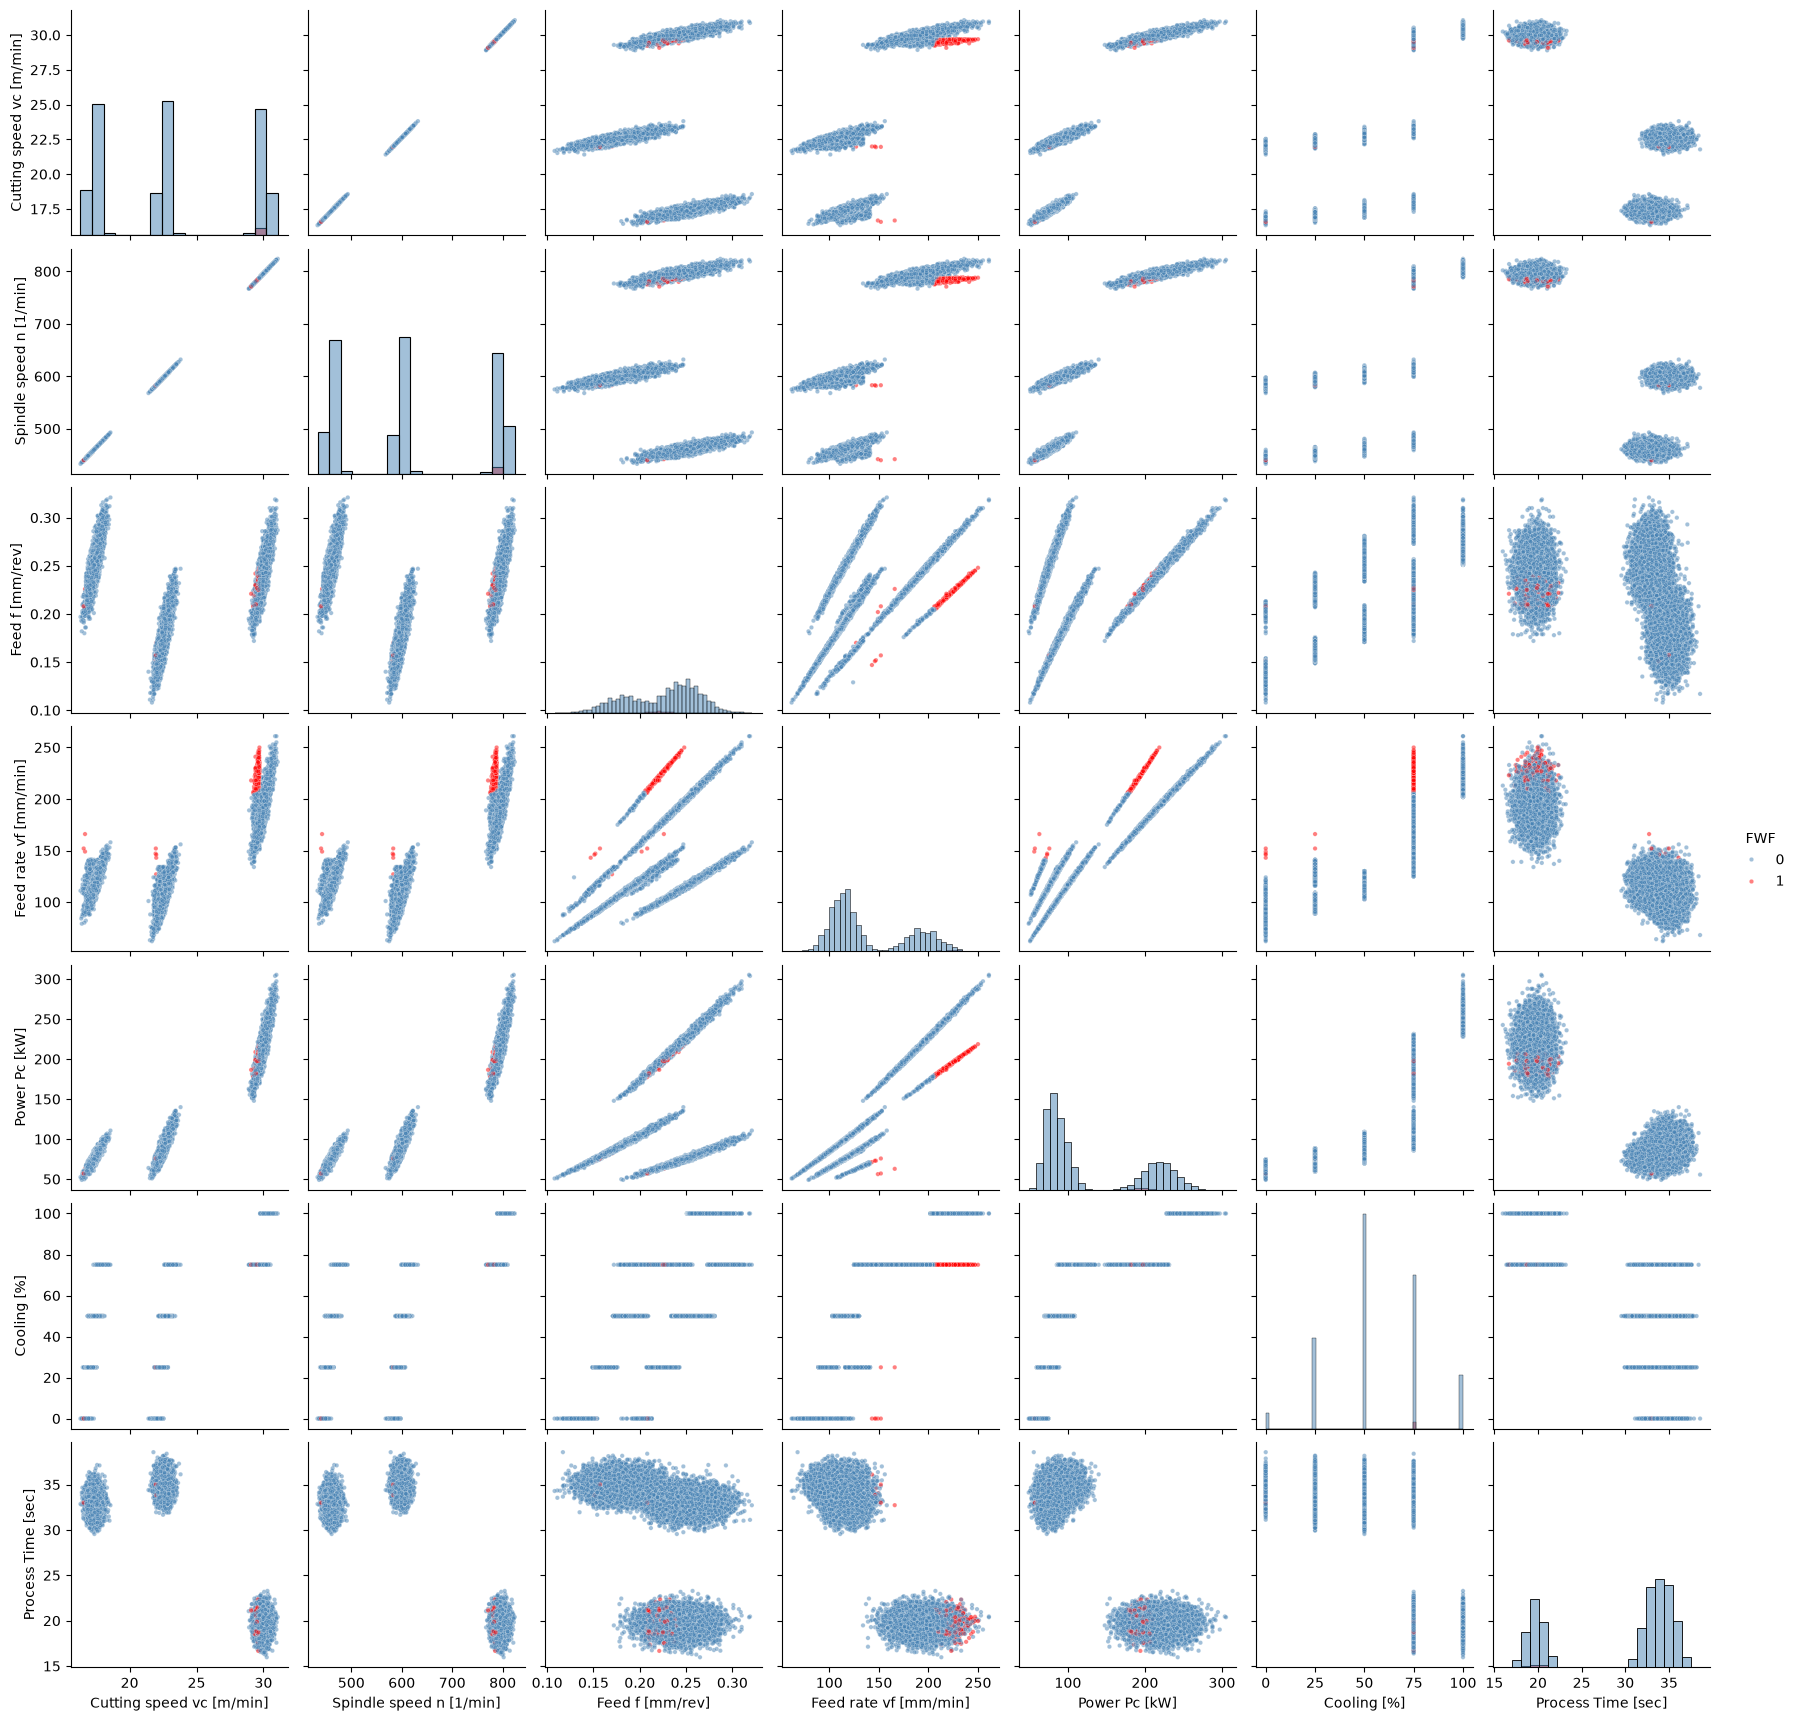

In [7]:
# Pairplot für FWF-Fehler erstellen
sns.pairplot(
    data=df,
    vars=numeric_features,
    hue="FWF",
    palette={0: "steelblue", 1: "red"},
    diag_kind="hist",
    plot_kws={"alpha": 0.5, "s": 10}
)

plt.show()

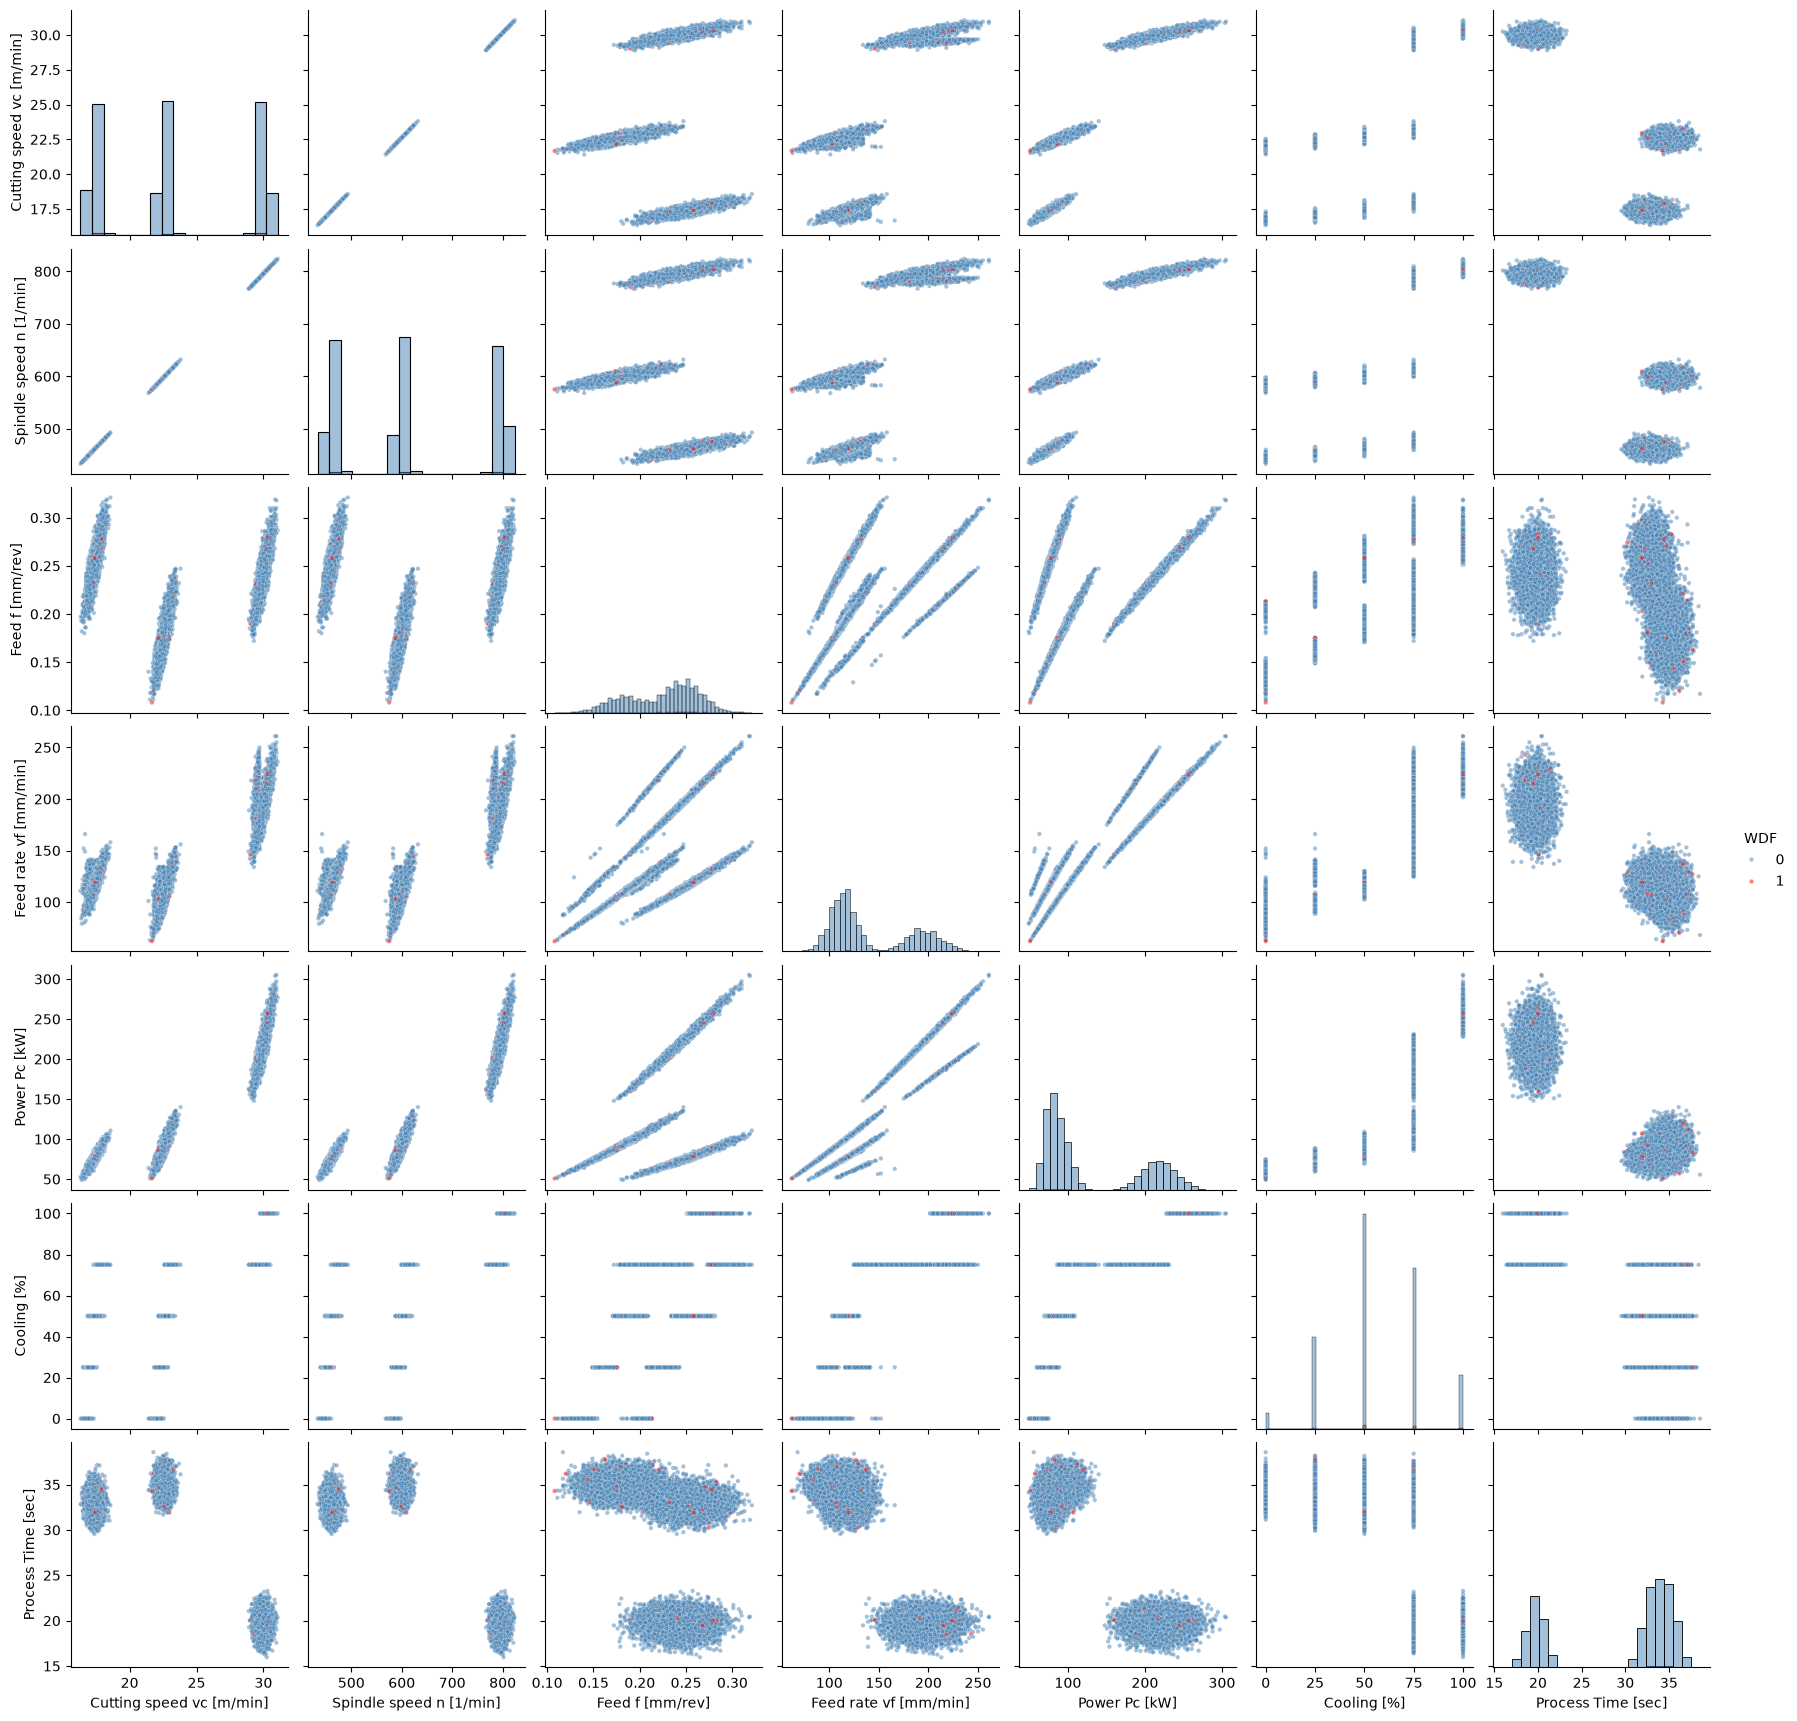

In [8]:
# Pairplot für WDF-Fehler erstellen
sns.pairplot(
    data=df,
    vars=numeric_features,
    hue="WDF",
    palette={0: "steelblue", 1: "red"},
    diag_kind="hist",
    plot_kws={"alpha": 0.5, "s": 10}
)
plt.show()

2. Do your findings align with the description given in the Subgroup failures paragraph?

Die Beobachtungen aus den Pairplots stimmen teilweise direkt mit der Beschreibung der Fehlerarten überein. Bei BEF sind niedrige Schnittgeschwindigkeiten in Kombination mit geringer Kühlung erkennbar. Bei FWF fällt besonders eine Gruppe mit hoher Vorschubgeschwindigkeit und vergleichsweise niedriger Schnittgeschwindigkeit innerhalb ihrer Gruppe auf.

Bei CCF ist eine Gruppe mit erhöhter Vorschubgeschwindigkeit und geringer Kühlung sichtbar. Die Beschreibung nennt zusätzlich einen ungeeigneten Bohrer und verlangt mindestens zwei dieser drei Bedingungen. Da der Bohrertyp im numerischen Pairplot nicht enthalten ist, lässt sich diese Regel noch nicht vollständig überprüfen.

WDF zeigt keine eindeutige Trennung anhand der numerischen Merkmale. Laut Beschreibung hängt dieser Fehler von einer unpassenden Kombination aus Material und Bohrertyp ab. Dafür müssen die beiden kategorialen Merkmale gesondert untersucht werden.

Die Pairplots liefern somit erste Hinweise auf die beschriebenen Zusammenhänge. Genaue Grenzwerte und die Bedeutung der Material-Bohrer-Kombinationen müssen noch überprüft werden.

3. Compute summary statistics for each feature grouped by failure type.

In [ ]:
# Fehler in Liste zusammenfassen
failure_cols = ["BEF", "CCF", "FWF", "WDF"]

for failure in failure_cols:
    print(failure)      # Fehlerart ausgeben

    display(
        df.groupby(failure)[numeric_features].describe().T  #Ausgabe numerischer Features
    )

BEF


BEF                                        0           1
Cutting speed vc [m/min] count  19785.000000  215.000000
                         mean      23.354428   20.381581
                         std        5.187134    2.388248
                         min       16.700000   16.330000
                         25%       17.590000   16.690000
                         50%       22.620000   21.850000
                         75%       29.790000   21.950000
                         max       31.070000   22.000000
Spindle speed n [1/min]  count  19785.000000  215.000000
                         mean     619.492292  540.618605
                         std      137.592425   63.314477
                         min      443.000000  433.000000
                         25%      467.000000  443.000000
                         50%      600.000000  580.000000
                         75%      790.000000  582.000000
                         max      824.000000  584.000000
Feed f [mm/rev]          count  19785.000000  215.000000
                         mean       0.225552    0.158465
                         std        0.036965    0.032633
                         min        0.122000    0.108000
                         25%        0.194000    0.134000
                         50%        0.234000    0.147000
                         75%        0.254000    0.193500
                         max        0.321000    0.226000
Feed rate vf [mm/min]    count  19785.000000  215.000000
                         mean     141.131160   94.497674
                         std       41.372243   17.853211
                         min       71.000000   62.000000
                         25%      110.000000   81.500000
                         50%      122.000000   91.000000
                         75%      184.000000  106.500000
                         max      261.000000  166.000000
Power Pc [kW]            count  19785.000000  215.000000
                         mean     129.699329   63.973953
                         std       65.399299    7.201436
                         min       51.990000   49.040000
                         25%       78.910000   58.370000
                         50%       93.650000   62.980000
                         75%      204.020000   69.340000
                         max      305.220000   82.060000
Cooling [%]              count  19785.000000  215.000000
                         mean      57.318676    4.418605
                         std       23.417359    9.558557
                         min        0.000000    0.000000
                         25%       50.000000    0.000000
                         50%       50.000000    0.000000
                         75%       75.000000    0.000000
                         max      100.000000   25.000000
Process Time [sec]       count  19785.000000  215.000000
                         mean      29.185496   34.458791
                         std        6.880807    1.266826
                         min       15.970000   31.230000
                         25%       20.330000   33.530000
                         50%       32.930000   34.570000
                         75%       34.520000   35.365000
                         max       38.400000   38.570000

CCF


CCF                                        0           1
Cutting speed vc [m/min] count  19656.000000  344.000000
                         mean      23.366800   20.789419
                         std        5.180577    4.062700
                         min       16.330000   16.570000
                         25%       17.600000   17.140000
                         50%       22.620000   22.180000
                         75%       29.790000   22.502500
                         max       31.070000   30.670000
Spindle speed n [1/min]  count  19656.000000  344.000000
                         mean     619.820411  551.447674
                         std      137.418493  107.758491
                         min      433.000000  440.000000
                         25%      467.000000  455.000000
                         50%      600.000000  588.000000
                         75%      790.000000  597.000000
                         max      824.000000  813.000000
Feed f [mm/rev]          count  19656.000000  344.000000
                         mean       0.225129    0.207820
                         std        0.037474    0.038790
                         min        0.111000    0.108000
                         25%        0.194000    0.169000
                         50%        0.234000    0.223000
                         75%        0.254000    0.233000
                         max        0.321000    0.297000
Feed rate vf [mm/min]    count  19656.000000  344.000000
                         mean     140.680861  137.715116
                         std       41.633981   30.617935
                         min       63.000000   62.000000
                         25%      109.000000  129.000000
                         50%      121.000000  133.000000
                         75%      184.000000  138.000000
                         max      261.000000  243.000000
Power Pc [kW]            count  19656.000000  344.000000
                         mean     129.623568   92.949913
                         std       65.466992   49.862546
                         min       49.040000   50.830000
                         25%       78.700000   68.115000
                         50%       93.700000   81.360000
                         75%      204.082500   86.090000
                         max      305.220000  269.060000
Cooling [%]              count  19656.000000  344.000000
                         mean      57.144129   34.229651
                         std       23.742782   24.525875
                         min        0.000000    0.000000
                         25%       50.000000   25.000000
                         50%       50.000000   25.000000
                         75%       75.000000   25.000000
                         max      100.000000  100.000000
Process Time [sec]       count  19656.000000  344.000000
                         mean      29.184789   32.521686
                         std        6.885205    4.648222
                         min       15.970000   18.020000
                         25%       20.330000   32.587500
                         50%       32.935000   33.735000
                         75%       34.520000   35.110000
                         max       38.570000   37.710000

FWF


FWF                                        0           1
Cutting speed vc [m/min] count  19722.000000  278.000000
                         mean      23.238244   29.297662
                         std        5.157513    1.670298
                         min       16.330000   16.570000
                         25%       17.580000   29.502500
                         50%       22.590000   29.600000
                         75%       29.790000   29.650000
                         max       31.070000   29.700000
Spindle speed n [1/min]  count  19722.000000  278.000000
                         mean     616.409999  777.158273
                         std      136.806343   44.310157
                         min      433.000000  440.000000
                         25%      466.000000  783.000000
                         50%      599.000000  785.000000
                         75%      790.000000  786.750000
                         max      824.000000  788.000000
Feed f [mm/rev]          count  19722.000000  278.000000
                         mean       0.224885    0.221029
                         std        0.037792    0.013100
                         min        0.108000    0.147000
                         25%        0.193000    0.214000
                         50%        0.234000    0.221000
                         75%        0.254000    0.230000
                         max        0.321000    0.248000
Feed rate vf [mm/min]    count  19722.000000  278.000000
                         mean     139.495741  221.086331
                         std       40.594139   16.057200
                         min       62.000000  127.000000
                         25%      109.000000  215.000000
                         50%      121.000000  222.000000
                         75%      182.000000  230.750000
                         max      261.000000  250.000000
Power Pc [kW]            count  19722.000000  278.000000
                         mean     128.120438  190.878921
                         std       65.389600   22.850181
                         min       49.040000   56.250000
                         25%       78.370000  186.492500
                         50%       92.660000  193.840000
                         75%      203.777500  201.132500
                         max      305.220000  218.660000
Cooling [%]              count  19722.000000  278.000000
                         mean      56.519369   73.111511
                         std       23.994032   11.181719
                         min        0.000000    0.000000
                         25%       50.000000   75.000000
                         50%       50.000000   75.000000
                         75%       75.000000   75.000000
                         max      100.000000   75.000000
Process Time [sec]       count  19722.000000  278.000000
                         mean      29.370326   20.151475
                         std        6.821790    2.612688
                         min       15.970000   16.670000
                         25%       20.430000   19.085000
                         50%       33.010000   19.800000
                         75%       34.560000   20.390000
                         max       38.570000   36.110000

WDF


WDF                                        0           1
Cutting speed vc [m/min] count  19700.000000  300.000000
                         mean      23.322494   23.320867
                         std        5.172484    5.293053
                         min       16.330000   16.620000
                         25%       17.590000   17.585000
                         50%       22.610000   22.595000
                         75%       29.780000   29.752500
                         max       31.070000   30.670000
Spindle speed n [1/min]  count  19700.000000  300.000000
                         mean     618.644924  618.610000
                         std      137.203822  140.398375
                         min      433.000000  441.000000
                         25%      467.000000  466.000000
                         50%      600.000000  599.000000
                         75%      790.000000  789.000000
                         max      824.000000  813.000000
Feed f [mm/rev]          count  19700.000000  300.000000
                         mean       0.224774    0.228593
                         std        0.037566    0.037224
                         min        0.111000    0.108000
                         25%        0.193000    0.199000
                         50%        0.233000    0.239000
                         75%        0.254000    0.256000
                         max        0.321000    0.297000
Feed rate vf [mm/min]    count  19700.000000  300.000000
                         mean     140.587563  143.406667
                         std       41.450488   42.741519
                         min       63.000000   62.000000
                         25%      109.000000  112.750000
                         50%      122.000000  124.000000
                         75%      183.000000  186.500000
                         max      261.000000  243.000000
Power Pc [kW]            count  19700.000000  300.000000
                         mean     128.959963  131.147800
                         std       65.387435   66.508206
                         min       49.040000   50.830000
                         25%       78.510000   78.182500
                         50%       93.250000   92.955000
                         75%      203.602500  203.117500
                         max      305.220000  269.060000
Cooling [%]              count  19700.000000  300.000000
                         mean      56.720812   58.666667
                         std       23.940215   24.016902
                         min        0.000000    0.000000
                         25%       50.000000   50.000000
                         50%       50.000000   50.000000
                         75%       75.000000   75.000000
                         max      100.000000  100.000000
Process Time [sec]       count  19700.000000  300.000000
                         mean      29.245126   29.049000
                         std        6.866051    6.907615
                         min       15.970000   17.800000
                         25%       20.360000   20.432500
                         50%       32.960000   32.855000
                         75%       34.530000   34.347500
                         max       38.570000   37.710000

In [10]:
for failure in failure_cols:
    print(failure)

    for feature in ["Material", "Drill Bit Type"]:
        print(feature)

        display(
            pd.crosstab(df[feature], df[failure])
        )

BEF
Material


BEF,0,1
Material,,
K,6613,61
N,6652,0
P,6520,154


Drill Bit Type


BEF,0,1
Drill Bit Type,,
H,6605,62
N,6535,153
W,6645,0


CCF
Material


CCF,0,1
Material,,
K,6515,159
N,6616,36
P,6525,149


... (6 outputs left out)

WDF
Material


WDF,0,1
Material,,
K,6568,106
N,6548,104
P,6584,90


Drill Bit Type


WDF,0,1
Drill Bit Type,,
H,6568,99
N,6584,104
W,6548,97


Für jede Fehlerart wurden die numerischen Merkmale nach Fehlerstatus gruppiert und mit Mittelwert, Standardabweichung, Minimum, Maximum und Quartilen beschrieben. Dabei bedeutet 0, dass die betrachtete Fehlerart nicht vorliegt, und 1, dass sie vorliegt. Zusätzlich wurden die Häufigkeiten der Materialien und Bohrertypen verglichen.

**BEF:** Die Fehlerfälle zeigen deutlich geringere Kühlwerte. Die mittlere Kühlung beträgt bei BEF etwa 4,42 %, gegenüber 57,32 % ohne BEF. Alle BEF-Fälle liegen bei höchstens 25 % Kühlung und einer Schnittgeschwindigkeit von höchstens 22 m/min. Außerdem treten sie ausschließlich bei den Materialien K und P auf. Diese Ergebnisse unterstützen die im Pairplot erkennbare Verbindung zwischen geringer Kühlung und niedriger Schnittgeschwindigkeit.

**CCF:** Die mittlere Kühlung ist bei Fehlerfällen mit 34,23 % niedriger als bei Beobachtungen ohne CCF mit 57,14 %. Die Vorschubgeschwindigkeit zeigt dagegen keine einfache Trennung: Ihr Mittelwert ist bei CCF etwas niedriger, der Median mit 133 mm/min jedoch höher als ohne CCF mit 121 mm/min. Ein einzelner Mittelwert reicht somit nicht aus, um diesen Fehler zu erklären. Die Kombination aus Vorschubgeschwindigkeit, Kühlung und passendem Bohrertyp muss berücksichtigt werden.

**FWF:** Die mittlere Vorschubgeschwindigkeit liegt bei Fehlerfällen mit 221,09 mm/min deutlich über den 139,50 mm/min ohne FWF. Zudem treten 270 der 278 Fehlerfälle bei Material N auf. Dadurch wird der Vergleich über den gesamten Datensatz stark von dieser Materialgruppe beeinflusst. Die mittlere Schnittgeschwindigkeit ist bei FWF insgesamt höher; ob sie innerhalb von Material N vergleichsweise niedrig ist, lässt sich aus diesen zusammengefassten Tabellen noch nicht feststellen.

**WDF:** Die numerischen Kennzahlen unterscheiden sich kaum zwischen Beobachtungen mit und ohne Fehler. Beispielsweise beträgt die mittlere Schnittgeschwindigkeit in beiden Gruppen ungefähr 23,32 m/min. Die getrennten Häufigkeiten von Material und Bohrertyp zeigen ebenfalls keine eindeutige Fehlerregel. Entscheidend ist hier, ob die beiden Kategorien zusammenpassen. Dafür müssen Material und Bohrertyp gemeinsam betrachtet werden.

Die Kennzahlen bestätigen mehrere Beobachtungen aus den Pairplots und zeigen, welche Merkmale genauer untersucht werden sollten. Die beobachteten Minimal- und Maximalwerte sind jedoch noch keine gesicherten Fehlergrenzen: Auch Beobachtungen ohne die jeweilige Fehlerart können in denselben Wertebereichen liegen.

4. Create at least two visualizations (e.g., histograms, box plots) that reveal differences between failure types.

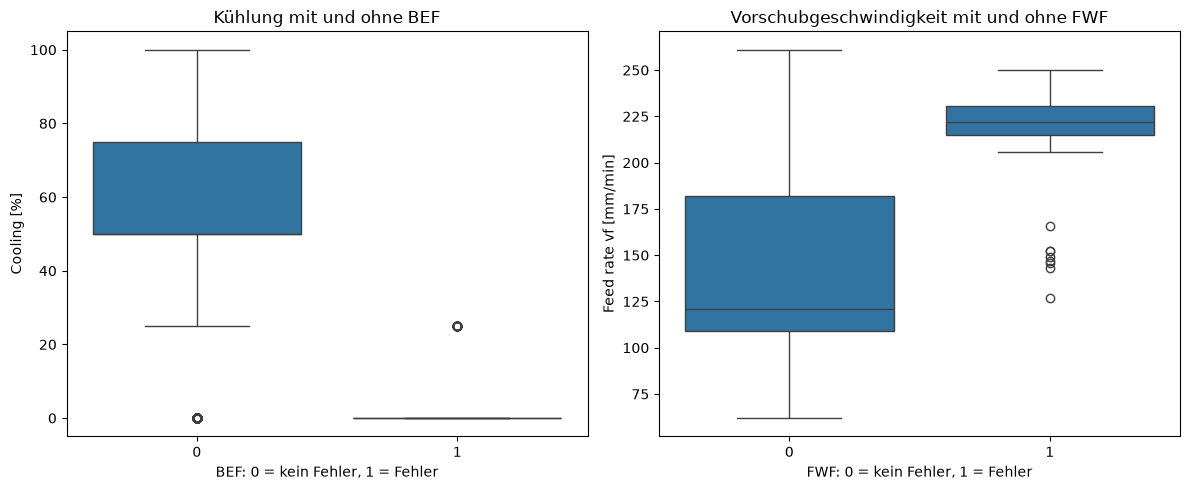

In [11]:
# Boxplots für BEF und FWf erstellen
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(
    data=df,
    x="BEF",
    y="Cooling [%]",
    ax=axes[0]
)

axes[0].set_title("Kühlung mit und ohne BEF")
axes[0].set_xlabel("BEF: 0 = kein Fehler, 1 = Fehler")

sns.boxplot(
    data=df,
    x="FWF",
    y="Feed rate vf [mm/min]",
    ax=axes[1]
)

axes[1].set_title("Vorschubgeschwindigkeit mit und ohne FWF")
axes[1].set_xlabel("FWF: 0 = kein Fehler, 1 = Fehler")

plt.tight_layout()
plt.show()

- Linie innerhalb der Box = Median
- Box = mittlere 50 % der Werte
- Äußere Linien und einzelne Punkte zeigen die weitere Streuung.

Die Boxplots verdeutlichen die Unterschiede zwischen Beobachtungen mit und ohne die betrachtete Fehlerart. Bei BEF liegt die Kühlung überwiegend bei 0 %, während die mittleren 50 % der Beobachtungen ohne BEF zwischen 50 und 75 % liegen. Da auch ohne BEF Kühlwerte von 0 % vorkommen, ist geringe Kühlung allein keine ausreichende Fehlerregel.

Bei FWF liegt der Median der Vorschubgeschwindigkeit mit 222 mm/min deutlich über den 121 mm/min ohne FWF. Es gibt jedoch Überschneidungen sowie einzelne Fehlerfälle mit niedrigeren Vorschubgeschwindigkeiten. Zur Ableitung einer Fehlerregel müssen deshalb weitere Merkmale und die Materialgruppen berücksichtigt werden.

5. If you are able to isolate failing samples, note down the thresholds; you will need them in Milestone 4.

In [ ]:
# Prüfen ob im BEF-Bereich (Cutting speed vc <= 22 und Cooling <= 25) BEF-Fehler auftreten
bef_range = (
    (df["Cutting speed vc [m/min]"] <= 22)
    & (df["Cooling [%]"] <= 25)
)

print("Beobachtungen im BEF-Bereich:")
display(df.loc[bef_range, "BEF"].value_counts().sort_index())

Beobachtungen im BEF-Bereich:


BEF
0    1605
1     215
Name: count, dtype: int64

In [14]:
# Wertebereiche nach Material und FWF-Status vergleichen
display(
    df.groupby(["Material", "FWF"])[
        ["Cutting speed vc [m/min]", "Feed rate vf [mm/min]"]
    ].agg(["min", "max"])
)

Cutting speed vc [m/min]        Feed rate vf [mm/min]     
                                  min    max                   min  max
Material FWF                                                           
K        0                      16.33  18.57                    79  158
         1                      16.57  16.67                   149  166
N        0                      28.90  31.07                   134  261
         1                      29.08  29.70                   206  250
P        0                      21.41  23.81                    62  156
         1                      21.94  21.99                   127  152

Für **BEF** wurden zunächst eine Schnittgeschwindigkeit von höchstens 22 m/min und eine Kühlung von höchstens 25 % als möglicher Fehlerbereich untersucht. Dieser Bereich enthält alle 215 BEF-Fälle, aber auch 1.605 Beobachtungen ohne BEF. Die Kombination erfasst somit sämtliche Fehlerfälle, ist für eine eindeutige Fehlerregel jedoch zu unspezifisch.

Für **FWF** wurden die beobachteten Wertebereiche nach Material getrennt. Bei Material K liegen die Fehlerfälle zwischen 16,57 und 16,67 m/min Schnittgeschwindigkeit sowie zwischen 149 und 166 mm/min Vorschubgeschwindigkeit. Bei Material N betragen die Bereiche 29,08–29,70 m/min und 206–250 mm/min, bei Material P 21,94–21,99 m/min und 127–152 mm/min. Diese Bereiche dienen als Anhaltspunkte für die weitere Untersuchung. Sie sind noch keine bestätigten Grenzwerte, insbesondere weil bei K und P nur wenige Fehlerfälle vorliegen.

Für **CCF** konnte bisher keine eindeutige Grenze isoliert werden. Vorschubgeschwindigkeit, Kühlung und die Eignung des Bohrers müssen gemeinsam untersucht werden. Bei **WDF** ist die Kombination aus Material und Bohrertyp entscheidend.

Die ermittelten Bereiche werden für die weitere interaktive Untersuchung und die spätere Entwicklung von Fehlerregeln festgehalten.

HTML erstellt mit:

uv run jupyter nbconvert --to html "Tasks/15 Self study - Session 2/Exercise_15.2.ipynb"